In [1]:
import numpy as np 
import scipy as sp
from scipy.optimize import least_squares
import matplotlib.pyplot as plt
from scipy.stats import t
import pandas as pd

In [2]:
def Vphi_model(x_i,DeltaV, gamma, a = 0.18):
    """Calcula o modelo de sino da velocidade toroidal eliminando os valores imaginários e divisões por zero

    Parâmetros:
        x_i (float): Intervalos de valores de raio 
        a (float): raio maior do tokamak 
        DeltaV (float): Amplitude da velocidade 
        Gama (float):  Expoente efetivo
    Retorna:
        V_phi (arr): V_phi(x_i) simulada seguindo modelo descrito em Wesson J., Tokamaks (2004).
    """
    # Recusa valores de a negativos e iguais a 0
    if a <= 0:
        return print("Please insert the original Radius of your Tokamak")

    # Adapta o código para listas e números
    x_i = np.asarray(x_i)

    # Tratamento de possíveis valores negativos
    power = gamma - 1
    base = np.maximum(1e-18, 1 - (x_i/a)**2)

    resultado = DeltaV * gamma * (2 * (x_i / a**2)) * (base**power)
    
    return resultado


def onion_peeling_method(n_cordas, y_i):
    """
    Função implementa o método de Pearse, descrito por Dasch (1992), num conjunto de cordas y_i.

    Parâmetros:
    n_cordas (int): número de cordas a ser utilizado no experimento
    r_max (int, float): valor do raio máximo a ser utilizado 

    Retorna:
    W_ij (arr): Matriz de pesos para o caso direto
    D_ij (arr): Matriz de deconvolução para a inversão através da inversão de W_ij
    """
    # Criação da malha 
    dr = y_i[1]-y_i[0]
    
    # Criação dos anéis utilizando o passo
    r_externo = y_i[:]+dr/2
    r_interno = y_i[:]-dr/2
    
    # Tratamento dos valores de borda
    r_externo[-1] = y_i[-1] + dr / 2
    r_interno[0] = 0
    
    # Criando a matriz W_ij
    W_ij = np.zeros((n_cordas,n_cordas))
    
    # Preenchendo a matriz W_ij
    for i in range(0,n_cordas):
        for j in range(0,n_cordas):
            if r_externo[j] > abs(y_i[i]):
                W_ij[i,j] = 2*(np.sqrt(max(0,r_externo[j]**2-y_i[i]**2))-np.sqrt(max(0,r_interno[j]**2-y_i[i]**2)))
            else:
                W_ij[i,j] = 0
    
    D_ij = np.linalg.inv(W_ij)
    return W_ij, D_ij

def Vapp(eps, Vphi, W_ij):
    """Aplicação do modelo direto propagando a velocidade de plasma.

    Parâmetros:
        x (list, float): Valores de emissividade ao longo do raio.
        Vphi (float): Valores de velocidade toroidal ao longo do raio.
        W_ij (arr): Matriz de peso calculada utilizando o método de Onion Peeling.
    Retorna: 
        Vapp (arr): Curvas de valores de velocidade aparente.    
    """
    
    U = W_ij @ (eps*Vphi)
    S = W_ij @ eps
    return U/S

def residual(params, r, V_obs, W, eps, sigma):
    DeltaV, gamma = params
    V_mod = Vapp(eps,Vphi_model(r,DeltaV,gamma), W)
    return (V_obs-V_mod)/sigma

def chi2(theta , *args):
    res = residual(theta, *args)
    return np.sum(res**2) 

In [3]:
df_emissividade = pd.read_csv('Utilities/dados_esp.csv', sep = ',')
df_emissividade.head()

,raio[m],emissivity[fotonsm^-3s^-2
0,0.000554,1.059362e+18
1,0.001600,1.053116e+18
2,0.002700,1.052663e+18
3,0.003800,1.051478e+18
4,0.004900,1.050116e+18


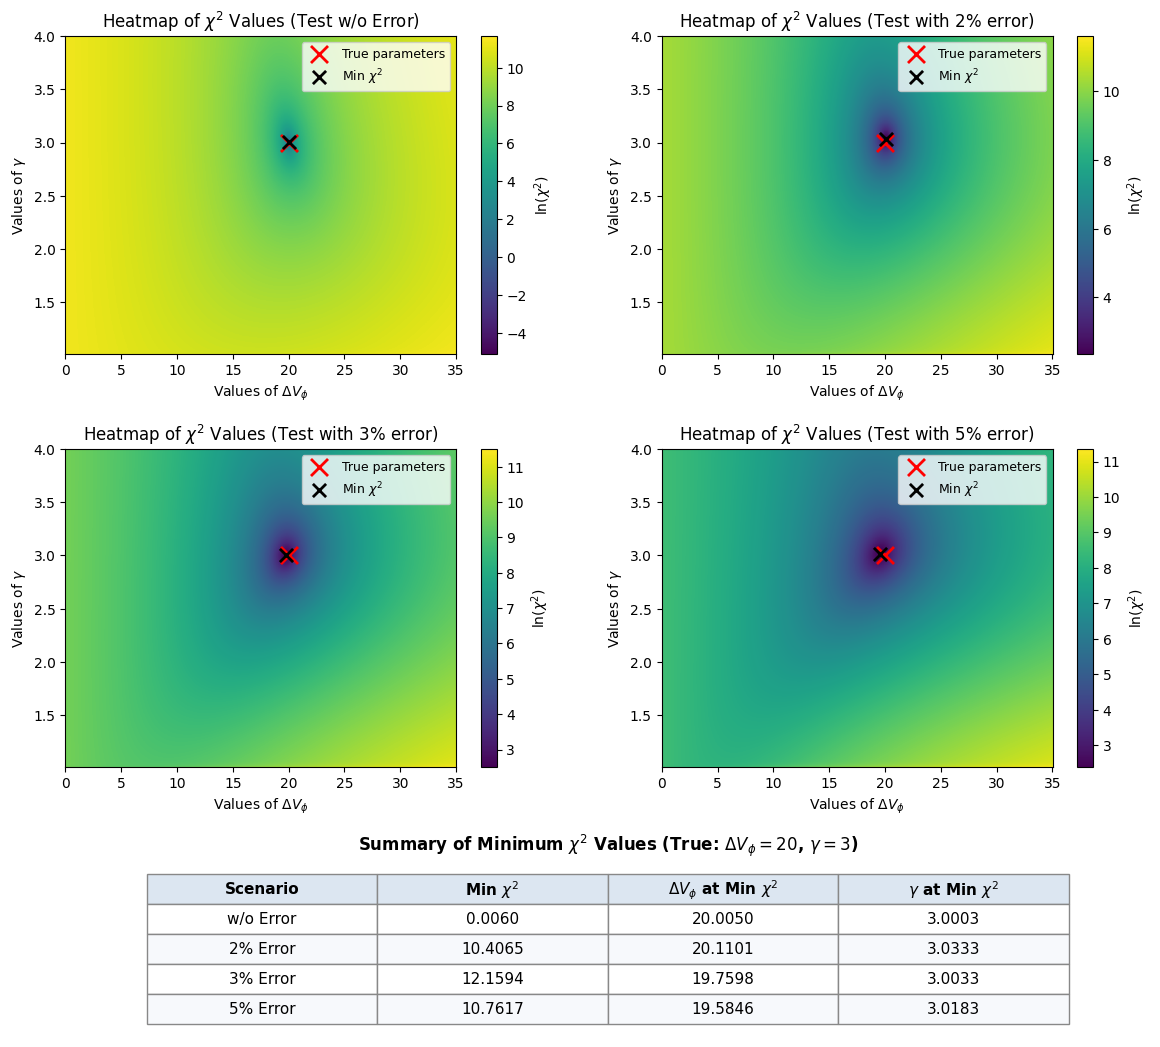

In [4]:
# --- Simulação Sintética: Grade 2x2 + Tabela Inferior ---
DeltaV_verdadeiro = 20
gamma_verdadeiro = 3

r = np.linspace(0, 0.18, 16)
Wij, Dij = onion_peeling_method(len(r), r)

eps = np.interp(
    r,
    df_emissividade['raio[m]'],
    df_emissividade['emissivity[fotonsm^-3s^-2']
)

Vphi_verdadeiro = Vphi_model(r, DeltaV_verdadeiro, gamma_verdadeiro)
Vapp_verdadeiro = Vapp(eps, Vphi_verdadeiro, Wij)

DeltaV_varredura = np.linspace(0, 35, 1000)
gamma_varredura = np.linspace(1.01, 4, 1000)

# Ordem original preservada para manter a mesma sequência do np.random.seed(42)
np.random.seed(42)
cenarios = [
    {"nome": "w/o Error", "titulo": "Test w/o Error",     "erro": 0.00, "ruido": False},
    {"nome": "2% Error",  "titulo": "Test with 2% error", "erro": 0.02, "ruido": True},
    {"nome": "3% Error",  "titulo": "Test with 3% error", "erro": 0.03, "ruido": True},
    {"nome": "5% Error",  "titulo": "Test with 5% error", "erro": 0.05, "ruido": True},
]

# Layout: 2 linhas superiores para os 4 mapas (2x2) e 1 linha inferior para a tabela
fig = plt.figure(figsize=(14, 13))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.55], hspace=0.35, wspace=0.22)

posicoes_grid = [(0, 0), (0, 1), (1, 0), (1, 1)]
resultados_tabela = []

for idx_plot, cenario in enumerate(cenarios):
    row_idx, col_idx = posicoes_grid[idx_plot]
    ax = fig.add_subplot(gs[row_idx, col_idx])

    sigma = cenario["erro"] * np.abs(Vapp_verdadeiro)
    sigma = np.maximum(sigma, 0.01 * np.max(np.abs(Vapp_verdadeiro)))

    Vapp_sintetica = Vapp_verdadeiro.copy()
    
    if cenario["ruido"]:
        Vapp_sintetica += np.random.normal(0, sigma)

    # Linhas = gamma; colunas = DeltaV
    chi2_grade = np.zeros((len(gamma_varredura), len(DeltaV_varredura)))
    for j, g_val in enumerate(gamma_varredura):
        for i, dV_val in enumerate(DeltaV_varredura):
            chi2_grade[j, i] = chi2((dV_val, g_val), r, Vapp_sintetica, Wij, eps, sigma)

    chi2_floor = max(1e-14, np.min(chi2_grade[chi2_grade > 0]) * 1e-3)
    chi2_log = np.log(np.maximum(chi2_grade, chi2_floor))

    idx_min = np.unravel_index(np.argmin(chi2_grade), chi2_grade.shape)
    gamma_min = gamma_varredura[idx_min[0]]
    DeltaV_min = DeltaV_varredura[idx_min[1]]
    min_chi2 = chi2_grade[idx_min]

    resultados_tabela.append([
        cenario["nome"],
        f"{min_chi2:.4f}",
        f"{DeltaV_min:.4f}",
        f"{gamma_min:.4f}"
    ])

    mesh = ax.pcolormesh(
        DeltaV_varredura,
        gamma_varredura,
        chi2_log,
        shading='auto',
        cmap='viridis'
    )
    fig.colorbar(mesh, ax=ax, label=r'$\ln(\chi^2)$')

    ax.scatter(
        DeltaV_verdadeiro,
        gamma_verdadeiro,
        marker='x',
        s=150,
        color='red',
        linewidths=2,
        label='True parameters'
    )
    ax.scatter(
        DeltaV_min,
        gamma_min,
        marker='x',
        s=90,
        color='black',
        linewidths=2,
        label=r'Min $\chi^2$'
    )

    ax.set_xlabel(r'Values of $\Delta V_\phi$')
    ax.set_ylabel(r'Values of $\gamma$')
    ax.set_title(rf'Heatmap of $\chi^2$ Values ({cenario["titulo"]})')
    ax.legend(loc='upper right', fontsize=9)

# --- Área Inferior (gs[2, :]): Tabela ocupando toda a largura ---
ax_table = fig.add_subplot(gs[2, :])
ax_table.axis('off')
ax_table.set_title(
    rf'Summary of Minimum $\chi^2$ Values (True: $\Delta V_\phi = {DeltaV_verdadeiro}$, $\gamma = {gamma_verdadeiro}$)',
    pad=8,
    fontsize=12,
    fontweight='bold'
)

colunas = [
    'Scenario',
    r'Min $\chi^2$',
    r'$\Delta V_\phi$ at Min $\chi^2$',
    r'$\gamma$ at Min $\chi^2$'
]

tabela = ax_table.table(
    cellText=resultados_tabela,
    colLabels=colunas,
    loc='center',
    cellLoc='center',
    colColours=['#dce6f1'] * len(colunas)
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(11)
tabela.scale(0.85, 1.8)

for (row, col), cell in tabela.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#f7f9fc')
    cell.set_edgecolor('#888888')

plt.savefig('Results/imgs/Heatmap_2x2_with_table.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
y0 = np.asarray([10,1.5])
dof = len(r) - 2

parameters = []
chi2 = []
errors = []
for idx_plot, cenario in enumerate(cenarios):
    sigma = cenario["erro"] * np.abs(Vapp_verdadeiro)
    sigma = np.maximum(sigma, 0.01 * np.max(np.abs(Vapp_verdadeiro)))
    Vapp_sintetica = Vapp_verdadeiro.copy()
    
    if cenario["ruido"]:
        Vapp_sintetica += np.random.normal(0, sigma)
    
    ajuste = least_squares(residual, x0 = y0 , method = 'trf', args = (r, Vapp_sintetica,Wij, eps, sigma))
    
    parameters.append(ajuste.x)
    
    chi2.append(np.sum(ajuste.fun**2))

    errors.append([abs((ajuste.x[0]-DeltaV_verdadeiro)/DeltaV_verdadeiro),abs((ajuste.x[1]-gamma_verdadeiro)/gamma_verdadeiro)])

In [6]:
parameters, chi2, errors

([array([20.,  3.]),
  array([20.00195941,  2.99539641]),
  array([20.21979023,  3.02481781]),
  array([20.09891605,  3.01534598])],
 [8.548357044845707e-27,
  10.967127226792286,
  18.164566791155796,
  8.604727687293781],
 [[1.7763568394002506e-16, 1.4802973661668753e-16],
  [9.797057613294413e-05, 0.0015345294780414835],
  [0.01098951147494347, 0.008272602978950752],
  [0.004945802446201597, 0.005115328227938143]])

In [7]:
### Teste para diferentes chutes iniciais.
DeltaV_teste = np.linspace(1,30,100)
gamma_teste = np.linspace(.5,6,100)

n_medidas = len(r)

resultados = []

for i in DeltaV_teste:
    for j in gamma_teste:
        y0 = np.array([i,j])
        
        ajuste = least_squares(residual, x0 = y0 , method = 'trf', args = (r, Vapp_sintetica,Wij, eps, sigma))

        resultados.append({
        'chute_inicial': y0,
        'DeltaV': ajuste.x[0],
        'gamma': ajuste.x[1],
        'chi2': np.sum(ajuste.fun**2),
        'success': ajuste.success,
        'nfev': ajuste.nfev
        })

/tmp/ipykernel_7523/1746046702.py:23: RuntimeWarning: overflow encountered in power
  resultado = DeltaV * gamma * (2 * (x_i / a**2)) * (base**power)


In [8]:
df_resultados = pd.DataFrame(resultados)
df_resultados.to_csv('Results/tables/convergencia_para_chutesdiferentes_porem_semruidos.csv')

In [9]:
resultados_ruidos = []
for idx_plot, cenario in enumerate(cenarios):
    sigma = cenario["erro"] * np.abs(Vapp_verdadeiro)
    sigma = np.maximum(sigma, 0.01 * np.max(np.abs(Vapp_verdadeiro)))
    Vapp_sintetica = Vapp_verdadeiro.copy()
    
    if cenario["ruido"]:
        Vapp_sintetica += np.random.normal(0, sigma)

    Vapp_medio = np.sum(Vapp_sintetica/sigma**2)/np.sum(1/sigma**2)
    SStotal = np.sum(((Vapp_sintetica - Vapp_medio)/sigma)**2)
    
    for i in DeltaV_teste:
        for j in gamma_teste:
            y0 = np.array([i,j])
            
            
            ajuste = least_squares(residual, x0 = y0 , method = 'trf', args = (r, Vapp_sintetica,Wij, eps, sigma))
            
            chi2 = np.sum(ajuste.fun**2)
            r2 = 1 - chi2/SStotal
            AIC = chi2 + 2*2
            BIC = chi2 + np.log(n_medidas)*2
    
            resultados_ruidos.append({
            'DeltaV_inicial': y0[0],
            'gamma_inicial': y0[1],
            'DeltaV': ajuste.x[0],
            'gamma': ajuste.x[1],
            'cenario': cenario["erro"],
            'chi2': chi2,
            'r2': r2,
            'chi2_red': chi2/dof,
            'AIC':AIC,
            'BIC': BIC,
            'success': ajuste.success,
            'optimality': ajuste.optimality,
            'nfev': ajuste.nfev
            })

/tmp/ipykernel_7523/1746046702.py:23: RuntimeWarning: overflow encountered in power
  resultado = DeltaV * gamma * (2 * (x_i / a**2)) * (base**power)


In [10]:
df_resultados_erros = pd.DataFrame(resultados_ruidos)

In [13]:
df_filtrado = df_resultados_erros[df_resultados_erros['cenario'] != 0.0]
df_filtrado.head()

df_filtrado.to_csv('Results/tables/quiquadradoprachutesdiferentes.csv')

DeltaV_inicial   NaN
gamma_inicial    NaN
DeltaV           NaN
gamma            NaN
cenario          NaN
chi2             NaN
r2               NaN
chi2_red         NaN
AIC              NaN
BIC              NaN
success          NaN
optimality       NaN
nfev             NaN
dtype: float64
DeltaV_inicial   NaN
gamma_inicial    NaN
DeltaV           NaN
gamma            NaN
cenario          NaN
chi2             NaN
r2               NaN
chi2_red         NaN
AIC              NaN
BIC              NaN
success          NaN
optimality       NaN
nfev             NaN
dtype: float64
DeltaV_inicial   NaN
gamma_inicial    NaN
DeltaV           NaN
gamma            NaN
cenario          NaN
chi2             NaN
r2               NaN
chi2_red         NaN
AIC              NaN
BIC              NaN
success          NaN
optimality       NaN
nfev             NaN
dtype: float64
DeltaV_inicial   NaN
gamma_inicial    NaN
DeltaV           NaN
gamma            NaN
cenario          NaN
chi2             NaN
r2        

0.05